In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Preprocessing tools
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
# Load the feature-engineered dataset.
file_path = "../data/processed/student_performance_featured.csv"
df = pd.read_csv(file_path)

# Separate the target variable from the input features.
y = df["Pass_Fail"].map({"Fail": 0, "Pass": 1})

# Exclude columns that would cause target leakage.
X = df.drop(columns=["Pass_Fail", "G3", "Grade_Category"])

# Identify categorical and numerical features.
categorical_features = X.select_dtypes(
    include=["str", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Display the dataset and modelling dimensions.
print("Dataset shape:", df.shape)
print("Input features:", X.shape)
print("Target shape:", y.shape)
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Dataset shape: (395, 37)
Input features: (395, 34)
Target shape: (395,)
Categorical features: 18
Numerical features: 16


In [4]:
# Encode categorical features into numerical binary columns.
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Standardise numerical features.
numerical_transformer = StandardScaler()

# Combine both transformations.
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline recreated successfully.")

Preprocessing pipeline recreated successfully.


In [5]:
# Divide the dataset into training and testing subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display the number of records in each subset.
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# Check the class distribution in each subset.
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training records: 276
Testing records: 119

Training target distribution:
Pass_Fail
1    185
0     91
Name: count, dtype: int64

Testing target distribution:
Pass_Fail
1    80
0    39
Name: count, dtype: int64


In [6]:
# Fit the preprocessing transformations on the training data.
X_train_transformed = preprocessor.fit_transform(X_train)

# Apply the fitted transformations to the testing data.
X_test_transformed = preprocessor.transform(X_test)

# Verify the transformed dataset dimensions.
print("Transformed training shape:", X_train_transformed.shape)
print("Transformed testing shape:", X_test_transformed.shape)

# Confirm that all transformed values are numerical.
print(
    "Training data is fully numeric:",
    np.issubdtype(X_train_transformed.dtype, np.number)
)

print(
    "Testing data is fully numeric:",
    np.issubdtype(X_test_transformed.dtype, np.number)
)

Transformed training shape: (276, 61)
Transformed testing shape: (119, 61)
Training data is fully numeric: True
Testing data is fully numeric: True


In [7]:
# Initialise the three classification models.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

# Train each model using the transformed training dataset.
for name, model in models.items():
    model.fit(X_train_transformed, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [8]:
# Store predictions and evaluation results for each model.
results = {}

for name, model in models.items():

    # Predict Pass/Fail outcomes using the testing dataset.
    y_pred = model.predict(X_test_transformed)

    # Calculate the model's accuracy.
    accuracy = accuracy_score(y_test, y_pred)

    # Store predictions and evaluation metrics.
    results[name] = {
        "predictions": y_pred,
        "accuracy": accuracy,
        "confusion_matrix": confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        ),
        "classification_report": classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Fail", "Pass"],
            output_dict=True,
            zero_division=0
        )
    }

    print(f"{name}: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Logistic Regression: 0.8992 (89.92%)
Decision Tree: 0.8992 (89.92%)
Random Forest: 0.8908 (89.08%)


In [9]:
# Display precision, recall and F1-score for each model.
for name, result in results.items():

    print(f"\n{'=' * 55}")
    print(name)
    print(f"{'=' * 55}")

    report = pd.DataFrame(
        result["classification_report"]
    ).transpose()

    print(report.round(3))


Logistic Regression
              precision  recall  f1-score  support
Fail              0.800   0.923     0.857   39.000
Pass              0.959   0.888     0.922   80.000
accuracy          0.899   0.899     0.899    0.899
macro avg         0.880   0.905     0.890  119.000
weighted avg      0.907   0.899     0.901  119.000

Decision Tree
              precision  recall  f1-score  support
Fail              0.776   0.974     0.864   39.000
Pass              0.986   0.862     0.920   80.000
accuracy          0.899   0.899     0.899    0.899
macro avg         0.881   0.918     0.892  119.000
weighted avg      0.917   0.899     0.902  119.000

Random Forest
              precision  recall  f1-score  support
Fail              0.795   0.897     0.843   39.000
Pass              0.947   0.888     0.916   80.000
accuracy          0.891   0.891     0.891    0.891
macro avg         0.871   0.892     0.880  119.000
weighted avg      0.897   0.891     0.892  119.000


In [10]:
# Display the confusion matrix for each classification model.
for name, result in results.items():

    print(f"\n{name}")
    print("Rows = Actual class | Columns = Predicted class")
    print("Class order: Fail (0), Pass (1)")

    matrix = pd.DataFrame(
        result["confusion_matrix"],
        index=["Actual Fail", "Actual Pass"],
        columns=["Predicted Fail", "Predicted Pass"]
    )

    print(matrix)


Logistic Regression
Rows = Actual class | Columns = Predicted class
Class order: Fail (0), Pass (1)
             Predicted Fail  Predicted Pass
Actual Fail              36               3
Actual Pass               9              71

Decision Tree
Rows = Actual class | Columns = Predicted class
Class order: Fail (0), Pass (1)
             Predicted Fail  Predicted Pass
Actual Fail              38               1
Actual Pass              11              69

Random Forest
Rows = Actual class | Columns = Predicted class
Class order: Fail (0), Pass (1)
             Predicted Fail  Predicted Pass
Actual Fail              35               4
Actual Pass               9              71


In [11]:
# Display the complete Random Forest classification report.
rf_report = pd.DataFrame(
    results["Random Forest"]["classification_report"]
).transpose()

print(rf_report.round(3).to_string())

              precision  recall  f1-score  support
Fail              0.795   0.897     0.843   39.000
Pass              0.947   0.888     0.916   80.000
accuracy          0.891   0.891     0.891    0.891
macro avg         0.871   0.892     0.880  119.000
weighted avg      0.897   0.891     0.892  119.000


In [12]:
# Build a consolidated comparison of all three models.
comparison_data = []

for name, result in results.items():

    report = result["classification_report"]

    comparison_data.append({
        "Model": name,
        "Accuracy": result["accuracy"],
        "Fail Precision": report["Fail"]["precision"],
        "Fail Recall": report["Fail"]["recall"],
        "Fail F1-Score": report["Fail"]["f1-score"],
        "Pass Precision": report["Pass"]["precision"],
        "Pass Recall": report["Pass"]["recall"],
        "Pass F1-Score": report["Pass"]["f1-score"],
        "Macro F1-Score": report["macro avg"]["f1-score"],
        "Weighted F1-Score": report["weighted avg"]["f1-score"]
    })

# Convert the collected results into a DataFrame.
comparison_df = pd.DataFrame(comparison_data)

# Display the comparison with four decimal places.
print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Fail Precision  Fail Recall  Fail F1-Score  Pass Precision  Pass Recall  Pass F1-Score  Macro F1-Score  Weighted F1-Score
Logistic Regression    0.8992          0.8000       0.9231         0.8571          0.9595       0.8875         0.9221          0.8896             0.9008
      Decision Tree    0.8992          0.7755       0.9744         0.8636          0.9857       0.8625         0.9200          0.8918             0.9015
      Random Forest    0.8908          0.7955       0.8974         0.8434          0.9467       0.8875         0.9161          0.8798             0.8923


In [13]:
# Create the metrics directory if it does not already exist.
import os

os.makedirs("../outputs/metrics", exist_ok=True)

# Save the model comparison table.
comparison_df.to_csv(
    "../outputs/metrics/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create the figures directory if it does not exist.
os.makedirs("../outputs/figures", exist_ok=True)

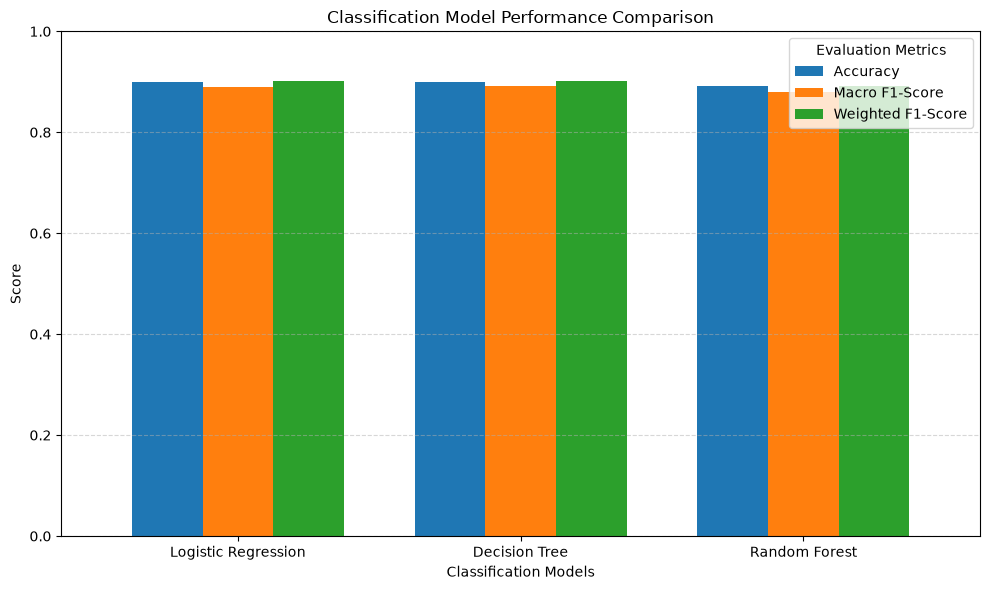

In [15]:
# Select the evaluation metrics for visual comparison.
metrics_to_plot = comparison_df.set_index("Model")[
    ["Accuracy", "Macro F1-Score", "Weighted F1-Score"]
]

# Create a grouped bar chart.
ax = metrics_to_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

# Save the chart for the final report.
plt.savefig(
    "../outputs/figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

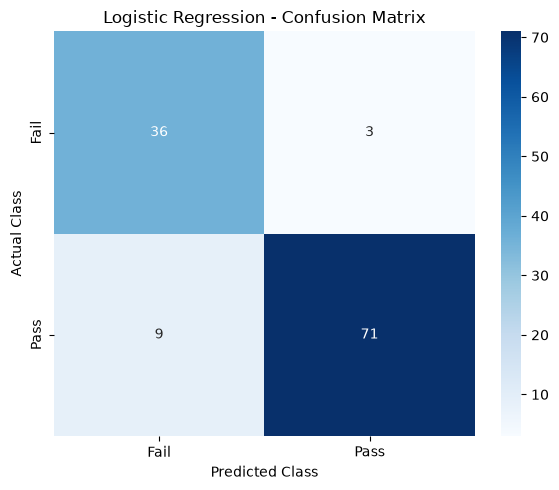

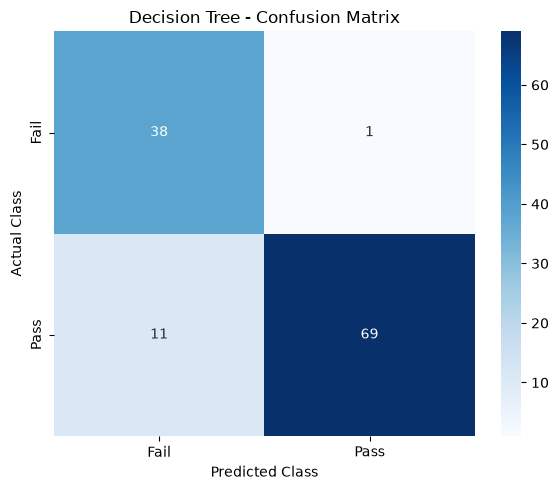

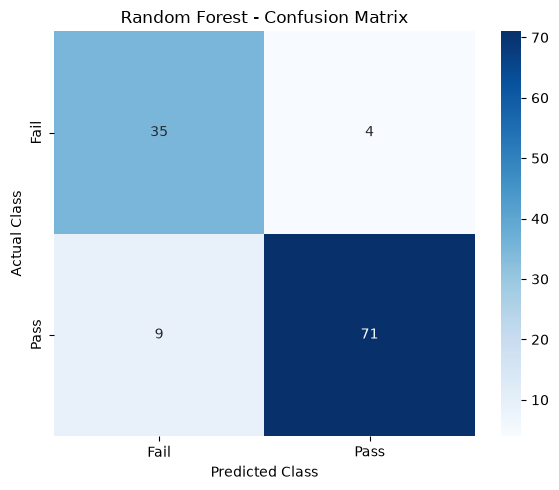

In [16]:
# Create a separate confusion matrix chart for each model.
for name, result in results.items():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        result["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail", "Pass"],
        yticklabels=["Fail", "Pass"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()

    # Save each confusion matrix.
    filename = name.lower().replace(" ", "_")

    plt.savefig(
        f"../outputs/figures/{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Model Evaluation, Comparison and Selection

### 1. Model Training

Three classification algorithms were trained using the prepared student performance dataset:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

The dataset was divided into 70% training data (276 records) and 30% testing data (119 records) using stratified sampling. The preprocessing transformations were fitted using the training data only to prevent data leakage.

### 2. Model Evaluation

The models were evaluated using accuracy, precision, recall, F1-score and confusion matrices.

| Model | Accuracy | Macro F1-score | Weighted F1-score |
|---|---:|---:|---:|
| Logistic Regression | 89.92% | 88.96% | 90.08% |
| Decision Tree | 89.92% | 89.18% | 90.15% |
| Random Forest | 89.08% | 87.98% | 89.23% |

### 3. Performance Analysis

The Logistic Regression and Decision Tree models achieved the highest accuracy of 89.92%.

The Decision Tree achieved the highest recall for the Fail class at 97.44%, correctly identifying 38 of the 39 students who actually failed. It also recorded the highest macro F1-score of 0.8918.

Logistic Regression achieved a Fail recall of 92.31%, while Random Forest achieved 89.74%.

These results indicate that the Decision Tree was particularly effective at identifying students at risk of failing, although it produced more false positive predictions than the other models.

### 4. Interpretability and Computational Complexity

- **Logistic Regression:** Relatively easy to interpret through its feature coefficients and generally computationally efficient.
- **Decision Tree:** Highly interpretable because its predictions follow understandable decision rules. Its complexity depends on the size and depth of the tree.
- **Random Forest:** Less interpretable because it combines multiple decision trees. It generally requires more computational resources than a single decision tree.

### 5. Selected Model

The Decision Tree Classifier was selected as the preferred model for this experiment.

The selection was based on its highest Fail-class recall, highest macro F1-score and joint-highest accuracy. Its ability to identify students who may be at risk of failing makes it suitable for the project's educational prediction objective.

Logistic Regression remains a competitive alternative because it achieved the same accuracy and produced fewer false positive Fail predictions.

### 6. Limitations

- The dataset contains only 395 student records.
- Evaluation was performed using a single stratified train/test split.
- The results may differ when applied to other student populations.
- The models have not undergone extensive hyperparameter tuning.
- The prediction uses earlier-period grades (G1 and G2), alongside other student information, to predict the final Pass/Fail outcome.

### 7. Output Files

The experiment generated the following outputs:

- `outputs/metrics/model_comparison.csv`
- `outputs/figures/model_performance_comparison.png`
- `outputs/figures/logistic_regression_confusion_matrix.png`
- `outputs/figures/decision_tree_confusion_matrix.png`
- `outputs/figures/random_forest_confusion_matrix.png`

The modelling phase successfully trained, evaluated and compared the three required classification algorithms.